## 1. Import libraries and load data

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA_PATH = Path("messy_retail_sales.csv")
raw = pd.read_csv(DATA_PATH)

print('rows,colums : ',raw.shape)
raw.head()

rows,colums :  (1258, 9)


,Order_ID,Order_Date,Product,Category,Quantity,Unit_Price,Discount,Customer_ID,Region
0,ORD00001,2025-02-02,Ceramic Mug,Home & Kitchen,3.0,256.86,0.00,C1194,West
1,ORD00002,2025-09-26,Bluetooth Speaker,Electronics,1.0,1784.72,0.00,C1191,West
2,ORD00003,2025-10-13,Notebook Set,Stationery,3.0,200.74,0.00,C1215,East
3,ORD00004,2025-10-30,Bluetooth Speaker,Electronics,1.0,1912.16,0.10,C1190,South
4,ORD00005,2025-03-13,Classic T-Shirt,Apparel,1.0,513.61,0.05,C1092,South


## 2. Inspect data quality

In [4]:
print("Data types:")
display(raw.dtypes.to_frame("Dtype"))

print("Missing values by column:")
display(raw.isnull().sum().sort_values(ascending=False).to_frame("missing_count"))

print("Exact duplicate rows:", raw.duplicated().sum())
print("Unique order IDs:", raw["Order_ID"].nunique())

Data types:


,Dtype
Order_ID,str
Order_Date,str
Product,str
Category,str
Quantity,float64
Unit_Price,float64
Discount,float64
Customer_ID,str
Region,str


Missing values by column:


,missing_count
Region,12
Quantity,8
Unit_Price,7
Order_ID,0
Order_Date,0
Category,0
Product,0
Discount,0
Customer_ID,0


Exact duplicate rows: 8
Unique order IDs: 1250


## 3. Clean the data

In [5]:
df = raw.copy()
df.shape
# Standardize text fields (remove leading/trailing and repeated whitespace)
for col in ["Product", "Category", "Region", "Customer_ID", "Order_ID"]:
    df[col] = df[col].astype("string").str.strip().str.replace(r"\\s+", " ", regex=True)

# Convert fields to the intended types; invalid dates/numbers become missing values
df["Order_Date"] = pd.to_datetime(df["Order_Date"], errors="coerce")
for col in ["Quantity", "Unit_Price", "Discount"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

rows_before = len(df)
duplicates = int(df.duplicated().sum())
df = df.drop_duplicates()
df.shape
# Rows missing a critical field cannot be reliably used for revenue calculations
critical_missing = int(df[["Order_Date", "Product", "Quantity", "Unit_Price"]].isna().any(axis=1).sum())
df = df.dropna(subset=["Order_Date", "Product", "Quantity", "Unit_Price"])

# Invalid values are excluded rather than silently converted into valid sales
invalid_values = int(((df["Quantity"] <= 0) | (df["Unit_Price"] <= 0)).sum())
df = df[(df["Quantity"] > 0) & (df["Unit_Price"] > 0)]

# Missing discounts are treated as no discount; missing descriptive fields get an explicit label
df["Discount"] = df["Discount"].fillna(0).clip(0, 1)
df["Category"] = df["Category"].fillna("Unknown")
df["Region"] = df["Region"].fillna("Unknown")

df["Revenue"] = df["Quantity"] * df["Unit_Price"] * (1 - df["Discount"])
df["Month"] = df["Order_Date"].dt.to_period("M").astype(str)

print(f"Rows before cleaning: {rows_before:,}")
print(f"Exact duplicate rows found: {duplicates:,}")
print(f"Rows with missing critical fields after deduplication: {critical_missing:,}")
print(f"Rows with invalid quantity/price after critical-field removal: {invalid_values:,}")
print(f"Rows after cleaning: {len(df):,}")
print("Remaining missing values:", int(df.isna().sum().sum()))
display(df.head())
df.shape

Rows before cleaning: 1,258
Exact duplicate rows found: 8
Rows with missing critical fields after deduplication: 19
Rows with invalid quantity/price after critical-field removal: 8
Rows after cleaning: 1,223
Remaining missing values: 0


,Order_ID,Order_Date,Product,Category,Quantity,Unit_Price,Discount,Customer_ID,Region,Revenue,Month
0,ORD00001,2025-02-02,Ceramic Mug,Home & Kitchen,3.0,256.86,0.00,C1194,West,770.5800,2025-02
1,ORD00002,2025-09-26,Bluetooth Speaker,Electronics,1.0,1784.72,0.00,C1191,West,1784.7200,2025-09
2,ORD00003,2025-10-13,Notebook Set,Stationery,3.0,200.74,0.00,C1215,East,602.2200,2025-10
3,ORD00004,2025-10-30,Bluetooth Speaker,Electronics,1.0,1912.16,0.10,C1190,South,1720.9440,2025-10
4,ORD00005,2025-03-13,Classic T-Shirt,Apparel,1.0,513.61,0.05,C1092,South,487.9295,2025-03


(1223, 11)

## 4. Key business metrics

In [6]:
total_revenue = df["Revenue"].sum()
total_units = int(df["Quantity"].sum())
unique_orders = df["Order_ID"].nunique()
unique_customers = df["Customer_ID"].nunique()
average_revenue_per_order = total_revenue / unique_orders if unique_orders else np.nan

summary = pd.DataFrame({
    "Metric": ["Net revenue (₹)", "Units sold", "Unique order IDs", "Unique customers", "Revenue per unique order ID (₹)"],
    "Value": [round(total_revenue, 2), total_units, unique_orders, unique_customers, round(average_revenue_per_order, 2)]
})
display(summary)

,Metric,Value
0,Net revenue (₹),1515058.39
1,Units sold,2492.00
2,Unique order IDs,1223.00
3,Unique customers,248.00
4,Revenue per unique order ID (₹),1238.80


## 5. Product and category performance

In [7]:
product_performance = (
    df.groupby("Product", as_index=False)
      .agg(Net_Revenue=("Revenue", "sum"),
           Units_Sold=("Quantity", "sum"),
           Transactions=("Order_ID", "nunique"))
      .sort_values("Net_Revenue", ascending=False)
)
category_performance = (
    df.groupby("Category", as_index=False)["Revenue"].sum()
      .rename(columns={"Revenue": "Net_Revenue"})
      .sort_values("Net_Revenue", ascending=False)
)
display(product_performance)
display(category_performance)

,Product,Net_Revenue,Units_Sold,Transactions
0,Bluetooth Speaker,287425.7535,165.0,79
4,Denim Jeans,277131.8110,221.0,108
3,Cotton Kurta,231213.7305,269.0,134
11,Wireless Mouse,161422.9540,210.0,108
2,Classic T-Shirt,119864.4230,251.0,115
9,Storage Basket,95719.4750,163.0,82
10,USB-C Cable,72615.2565,253.0,122
8,Steel Water Bottle,67458.2845,201.0,104
1,Ceramic Mug,61067.8595,254.0,130
5,Desk Organizer,60438.8110,141.0,65


,Category,Net_Revenue
0,Apparel,628209.9645
1,Electronics,521463.9640
2,Home & Kitchen,224245.6190
3,Stationery,141138.8435


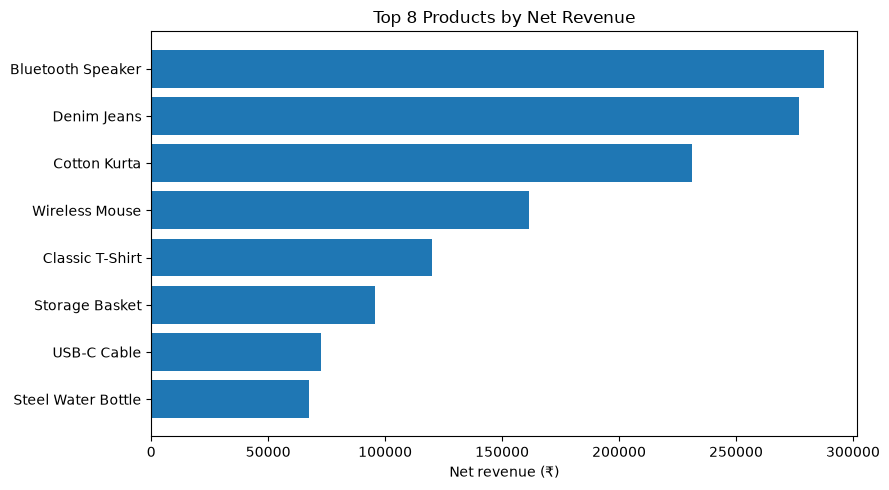

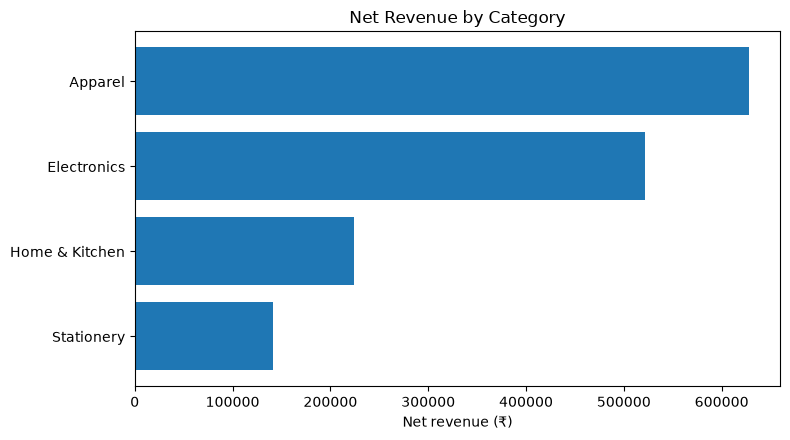

In [20]:
top_products = product_performance.head(8).sort_values("Net_Revenue")
plt.figure(figsize=(9, 5))
plt.barh(top_products["Product"], top_products["Net_Revenue"])
plt.xlabel("Net revenue (₹)")
plt.title("Top 8 Products by Net Revenue")
plt.tight_layout()
plt.savefig("top_products.png", dpi=300)
plt.show()

category_plot = category_performance.sort_values("Net_Revenue")
plt.figure(figsize=(8, 4.5))
plt.barh(category_plot["Category"], category_plot["Net_Revenue"])
plt.xlabel("Net revenue (₹)")
plt.title("Net Revenue by Category")
plt.tight_layout()
plt.savefig("category.png", dpi=300)
plt.show()

## 6. Monthly revenue trend

,Month,Revenue
0,2025-01,129338.7115
1,2025-02,126484.0000
2,2025-03,118505.0455
3,2025-04,135366.4690
4,2025-05,106897.5115
5,2025-06,107899.0605
6,2025-07,189498.5565
7,2025-08,123858.0560
8,2025-09,82855.2845
9,2025-10,159846.2780


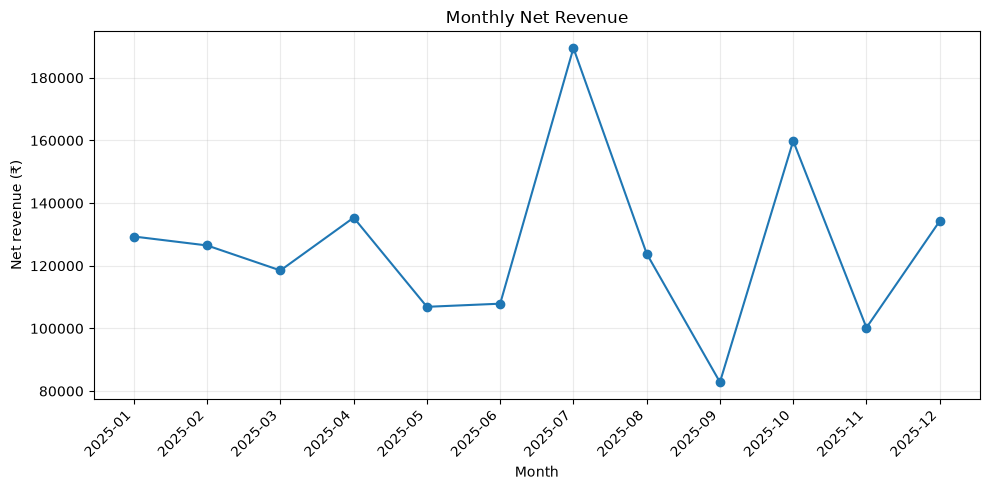

In [19]:
monthly_revenue = (
    df.groupby("Month", as_index=False)["Revenue"].sum()
      .sort_values("Month")
)
display(monthly_revenue)

plt.figure(figsize=(10, 5))
plt.plot(monthly_revenue["Month"], monthly_revenue["Revenue"], marker="o")
plt.xticks(rotation=45, ha="right")
plt.xlabel("Month")
plt.ylabel("Net revenue (₹)")
plt.title("Monthly Net Revenue")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.savefig("monthly_revenue.png", dpi=300)
plt.show()

## 7. Regional performance

In [10]:
region_performance = (
    df.groupby("Region", as_index=False)["Revenue"].sum()
      .rename(columns={"Revenue": "Net_Revenue"})
      .sort_values("Net_Revenue", ascending=False)
)
display(region_performance)

,Region,Net_Revenue
2,South,487199.8220
4,West,390278.5375
1,North,372736.6040
0,East,251376.8985
3,Unknown,13466.5290


## 8. Write recommendations from the results

In [12]:
top_product = product_performance.iloc[0]
top_category = category_performance.iloc[0]
best_month = monthly_revenue.loc[monthly_revenue["Revenue"].idxmax()]
weakest_month = monthly_revenue.loc[monthly_revenue["Revenue"].idxmin()]
top_region = region_performance.iloc[0]

print(f"1. Review stock availability for '{top_product['Product']}', the highest-revenue product in this dataset.")
print(f"2. Prioritize merchandising tests for '{top_category['Category']}', the leading category by revenue.")
print(f"3. Investigate what contributed to the peak in {best_month['Month']}; compare promotions, stock, and order volume before repeating it.")
print(f"4. Investigate the low-revenue month {weakest_month['Month']} before changing budgets; check seasonality, stockouts, and marketing activity.")
print(f"5. Compare customer acquisition, fulfillment costs, and demand in the '{top_region['Region']}' region before allocating more budget there.")

1. Review stock availability for 'Bluetooth Speaker', the highest-revenue product in this dataset.
2. Prioritize merchandising tests for 'Apparel', the leading category by revenue.
3. Investigate what contributed to the peak in 2025-07; compare promotions, stock, and order volume before repeating it.
4. Investigate the low-revenue month 2025-09 before changing budgets; check seasonality, stockouts, and marketing activity.
5. Compare customer acquisition, fulfillment costs, and demand in the 'South' region before allocating more budget there.


In [14]:
df.to_csv("cleaned_retail_sales.csv",index=False)

In [15]:
df.head()

,Order_ID,Order_Date,Product,Category,Quantity,Unit_Price,Discount,Customer_ID,Region,Revenue,Month
0,ORD00001,2025-02-02,Ceramic Mug,Home & Kitchen,3.0,256.86,0.00,C1194,West,770.5800,2025-02
1,ORD00002,2025-09-26,Bluetooth Speaker,Electronics,1.0,1784.72,0.00,C1191,West,1784.7200,2025-09
2,ORD00003,2025-10-13,Notebook Set,Stationery,3.0,200.74,0.00,C1215,East,602.2200,2025-10
3,ORD00004,2025-10-30,Bluetooth Speaker,Electronics,1.0,1912.16,0.10,C1190,South,1720.9440,2025-10
4,ORD00005,2025-03-13,Classic T-Shirt,Apparel,1.0,513.61,0.05,C1092,South,487.9295,2025-03


In [16]:
df.shape

(1223, 11)

In [17]:
product_performance.to_csv("product_performance.csv",index=False)
monthly_revenue.to_csv("monthly_revenue.csv",index=False)